# 03 · Features LRFMC y transformación

Construcción de las cinco métricas que alimentan el clustering y de las variables que se usarán
para describir los segmentos.

1. **Features LRFMC** (Fase 4): secciones 1–5.
2. **Transformación y escalado** (Fase 5): secciones 6–9.

- **Entrada:** `data/interim/flight_clean.parquet` (`uv run poe clean`).
- **Salidas:** `data/processed/lrfmc.parquet` y `profile.parquet` (`uv run poe features`);
  `data/processed/lrfmc_scaled.parquet`, `transform_comparison.csv` y
  `models/preprocessor.joblib` (`uv run poe transform`).
- El código vive en `src/segmentacion/features/lrfmc.py` y
  `src/segmentacion/preprocessing/transform.py`. Versión web: página **LRFMC** del sitio.

In [1]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

from segmentacion.config import get_config
from segmentacion.features.lrfmc import (
    DAYS_PER_MONTH,
    DAYS_PER_RECENCY_MONTH,
    LRFMC_COLUMNS,
    build_lrfmc,
    build_profile_features,
)
from segmentacion.preprocessing.transform import (
    compare_preprocessors,
    load_preprocessor,
    make_preprocessor,
    skewness,
)
from segmentacion.viz import eda_charts as ec
from segmentacion.viz import model_charts as mc
from segmentacion.viz.notebook import enable_notebook_renderer

enable_notebook_renderer()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
config = get_config()

df = pd.read_parquet(config.clean_file)
print(f"{len(df):,} socios limpios")

62,044 socios limpios


## 1. Definición de las métricas

| Métrica | Fórmula | Pregunta de negocio |
|---|---|---|
| **L** · *Length* | días entre `FFP_DATE` y `LOAD_TIME` / 30,44 | ¿Hace cuánto que es socio? |
| **R** · *Recency* | `LAST_TO_END` / 30 | ¿Hace cuántos meses que no vuela? |
| **F** · *Frequency* | `FLIGHT_COUNT` | ¿Cuántas veces voló en la ventana? |
| **M** · *Monetary* | `SEG_KM_SUM` | ¿Cuántos km voló? |
| **C** · *Coefficient* | `avg_discount` | ¿Paga tarifa completa (1,0) o compra en oferta? |

**¿Por qué M son kilómetros y no dinero?** En aviación el precio depende de la distancia y la
clase; km volados combinados con el descuento (C) representan mejor el valor que el gasto bruto.
El ingreso (`SUM_YR_1`, `SUM_YR_2`) se reserva para perfilar y validar los segmentos.

In [2]:
lrfmc = build_lrfmc(df)
lrfmc.head()

,MEMBER_NO,L,R,F,M,C
0,54993,88.90,0.03,210.00,"580,717.00",0.96
1,28065,85.32,0.23,140.00,"293,678.00",1.25
2,55106,85.91,0.37,135.00,"283,712.00",1.25
3,21189,67.25,3.23,23.00,"281,336.00",1.09
4,39546,59.66,0.17,152.00,"309,928.00",0.97


## 2. Comprobación a mano con un socio

In [3]:
member = df.iloc[0]
days = (member["LOAD_TIME"] - member["FFP_DATE"]).days
print(f"Socio {member['MEMBER_NO']}")
print(f"  L = {days} días / {DAYS_PER_MONTH:.4f} = {days / DAYS_PER_MONTH:.2f} meses")
print(
    f"  R = {member['LAST_TO_END']} días / {DAYS_PER_RECENCY_MONTH} = "
    f"{member['LAST_TO_END'] / DAYS_PER_RECENCY_MONTH:.2f} meses"
)
print(f"  F = {member['FLIGHT_COUNT']} vuelos · M = {member['SEG_KM_SUM']:,} km")
print(f"  C = {member['avg_discount']:.4f}")
lrfmc.iloc[[0]]

Socio 54993
  L = 2706 días / 30.4375 = 88.90 meses
  R = 1 días / 30 = 0.03 meses
  F = 210 vuelos · M = 580,717 km
  C = 0.9616


,MEMBER_NO,L,R,F,M,C
0,54993,88.90,0.03,210.00,"580,717.00",0.96


## 3. Estadísticos y validaciones

La ventana de observación va del 01/04/2012 al 31/03/2014 y la última alta es del 31/03/2013,
así que L debe ser ≥ 12 meses y R ≤ 24,4 meses.

In [4]:
metrics = lrfmc[list(LRFMC_COLUMNS)]
table = metrics.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
table["asimetría"] = metrics.skew()
table

,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetría
L,"62,044.00",48.91,27.86,11.99,12.45,24.15,41.99,71.69,109.27,112.92,0.52
R,"62,044.00",5.75,6.05,0.03,0.03,0.97,3.50,8.67,22.83,24.37,1.21
F,"62,044.00",11.97,14.11,2.00,2.00,3.00,7.00,15.00,70.00,213.00,3.20
M,"62,044.00","17,321.69","21,052.73",368.00,"1,228.00","4,874.00","10,200.00","21,522.50","101,367.37","580,717.00",3.87
C,"62,044.00",0.72,0.18,0.14,0.34,0.61,0.71,0.81,1.41,1.50,0.98


In [5]:
checks = {
    "un socio por fila": lrfmc["MEMBER_NO"].is_unique and len(lrfmc) == len(df),
    "sin NaN ni infinitos": bool(np.isfinite(metrics.to_numpy()).all()),
    "L, R, F, M, C ≥ 0": bool((metrics >= 0).all().all()),
    "L ≥ 12 meses": metrics["L"].min() >= 11.9,
    "R ≤ 24,4 meses (ventana de 2 años)": metrics["R"].max() <= 24.4,
    "F ≥ 2 vuelos": metrics["F"].min() >= 2,
}
pd.Series(checks, name="cumple").to_frame()

,cumple
un socio por fila,True
sin NaN ni infinitos,True
"L, R, F, M, C ≥ 0",True
L ≥ 12 meses,True
"R ≤ 24,4 meses (ventana de 2 años)",True
F ≥ 2 vuelos,True


F y M conservan la cola larga que se vio en el EDA (asimetría > 3): la Fase 5 decidirá la
transformación (log1p o Yeo-Johnson) y el escalado.

alt.Chart(...)
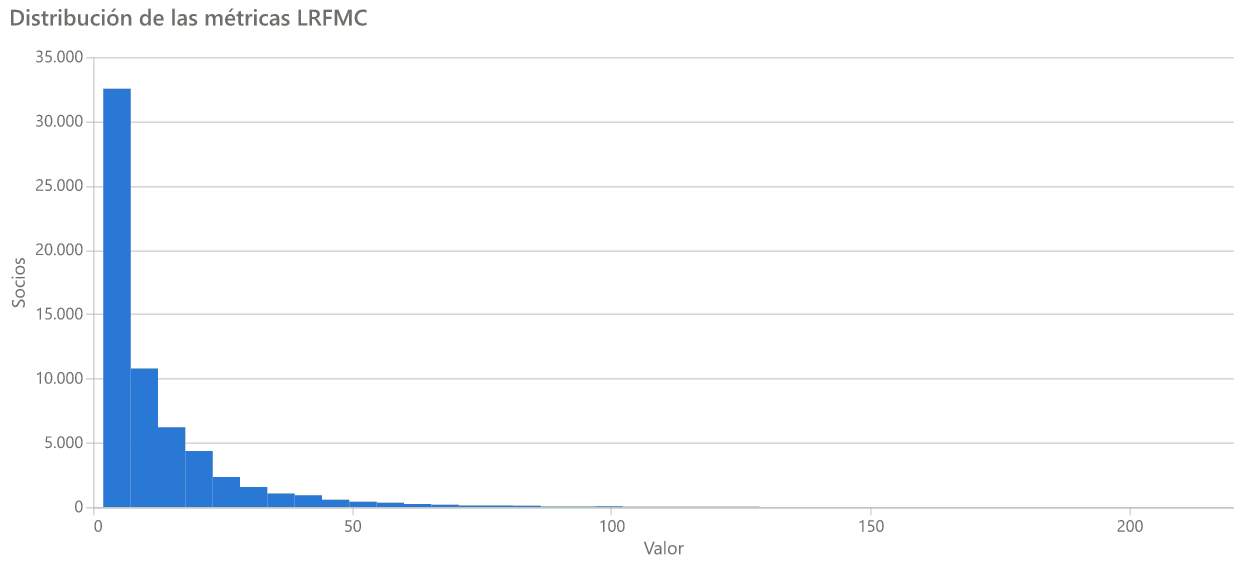

In [6]:
ec.distribution_chart(df)

## 4. Variables de perfilado

No entran al clustering; sirven para describir y nombrar los segmentos.

| Variable | Definición | Para qué |
|---|---|---|
| `revenue_total` | `SUM_YR_1 + SUM_YR_2` | Valor económico real del segmento |
| `revenue_trend` | `(Y2 − Y1) / (Y1 + Y2)` ∈ [−1, 1] | Riesgo de abandono (−1 = dejó de ingresar) |
| `km_per_flight` | `SEG_KM_SUM / FLIGHT_COUNT` | Rutas cortas vs largas |
| `points_ratio` | `Point_NotFlight / Points_Sum` ∈ [0, 1] | Peso de los puntos no originados en vuelos |

Además se conservan nivel, género, edad, ubicación, intervalos entre vuelos y canjes.

In [7]:
profile = build_profile_features(df)
derived = ["revenue_total", "revenue_trend", "km_per_flight", "points_ratio"]
profile[derived].describe().T

,count,mean,std,min,25%,50%,75%,max
revenue_total,"62,044.00","11,066.12","15,373.36",162.00,"2,800.00","5,984.00","13,117.00","473,748.00"
revenue_trend,"62,044.00",-0.01,0.67,-1.00,-0.54,-0.00,0.50,1.00
km_per_flight,"62,044.00","1,583.94","1,132.14",184.00,"1,062.14","1,363.62","1,766.66","13,320.50"
points_ratio,"62,044.00",0.00,0.00,0.00,0.00,0.00,0.00,0.47


### ¿Captura `revenue_trend` el abandono?

Si la tendencia −1 significa «dejó de volar», esos socios deberían tener una recencia alta.

In [8]:
bands = pd.cut(
    profile["revenue_trend"],
    [-1.01, -0.99, -0.33, 0.33, 0.99, 1.0],
    labels=["−1 (sin ingreso año 2)", "cae", "estable", "crece", "+1 (solo año 2)"],
)
lrfmc.assign(tendencia=bands).groupby("tendencia", observed=True).agg(
    socios=("MEMBER_NO", "size"),
    recencia_mediana=("R", "median"),
    vuelos_mediana=("F", "median"),
)

,socios,recencia_mediana,vuelos_mediana
tendencia,,,
−1 (sin ingreso año 2),11006,16.53,3.00
cae,9294,4.67,9.00
estable,21920,1.97,12.00
crece,10302,1.43,10.00
+1 (solo año 2),9522,2.80,3.00


Los socios con tendencia −1 llevan más de un año sin volar (recencia mediana > 16 meses): la
variable sí captura el abandono y será clave para nombrar un segmento «en riesgo».

## 5. Artefactos guardados

`uv run poe features` escribe ambos archivos; aquí se comprueba que coinciden con lo calculado.

In [9]:
saved = pd.read_parquet(config.lrfmc_file)
pd.testing.assert_frame_equal(saved, lrfmc.reset_index(drop=True), check_dtype=False)
saved_profile = pd.read_parquet(config.profile_file)
print(f"{config.lrfmc_file.name}: {saved.shape}")
print(f"{config.profile_file.name}: {saved_profile.shape}")

lrfmc.parquet: (62044, 6)
profile.parquet: (62044, 16)


## 6. Comparación de transformaciones y escalados

K-Means usa distancia euclídea, así que importan dos cosas: que ninguna feature tenga una cola
que domine las distancias (asimetría) y que todas pesen lo mismo (escala). Se comparan
3 transformaciones × 2 escaladores con K-Means para *k* = 4, 5 y 6.

Este cálculo tarda alrededor de un minuto; `uv run poe transform` lo guarda en
`transform_comparison.csv`, que es lo que lee la página web.

In [10]:
params = config.preprocessing
features = lrfmc[list(LRFMC_COLUMNS)]
comparison = compare_preprocessors(
    features, params.compare_ks, params.silhouette_sample_size, config.random_state
)
summary_cols = [
    "transform",
    "scaler",
    "max_abs_skew",
    "std_ratio",
    *[f"min_cluster_pct_k{k}" for k in params.compare_ks],
    "silhouette_mean",
]
comparison[summary_cols].sort_values("silhouette_mean", ascending=False)

,transform,scaler,max_abs_skew,std_ratio,min_cluster_pct_k4,min_cluster_pct_k5,min_cluster_pct_k6,silhouette_mean
0,none,standard,3.87,1.00,0.09,0.08,0.03,0.28
1,none,robust,3.87,2.16,0.04,0.03,0.02,0.25
3,log1p,robust,0.54,1.59,0.05,0.05,0.05,0.23
5,yeo-johnson,robust,0.09,1.61,0.18,0.08,0.06,0.21
4,yeo-johnson,standard,0.09,1.00,0.19,0.14,0.13,0.21
2,log1p,standard,0.54,1.00,0.24,0.17,0.14,0.21


alt.LayerChart(...)
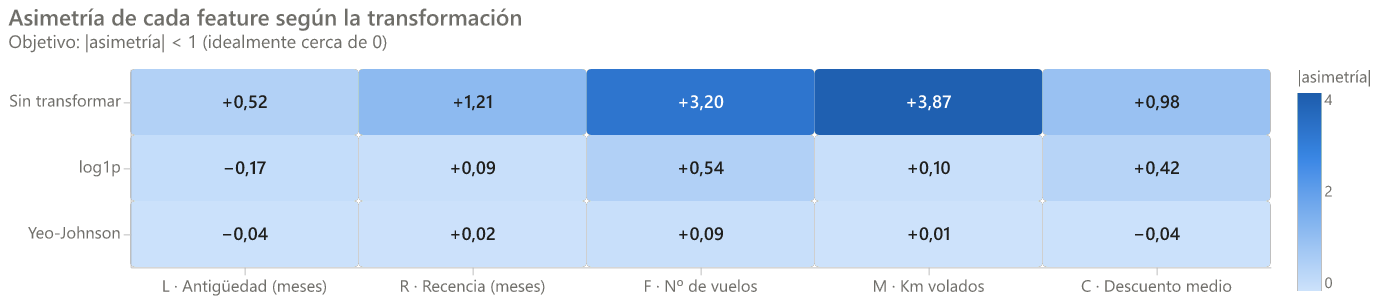

In [11]:
mc.skew_comparison_chart(comparison)

alt.LayerChart(...)
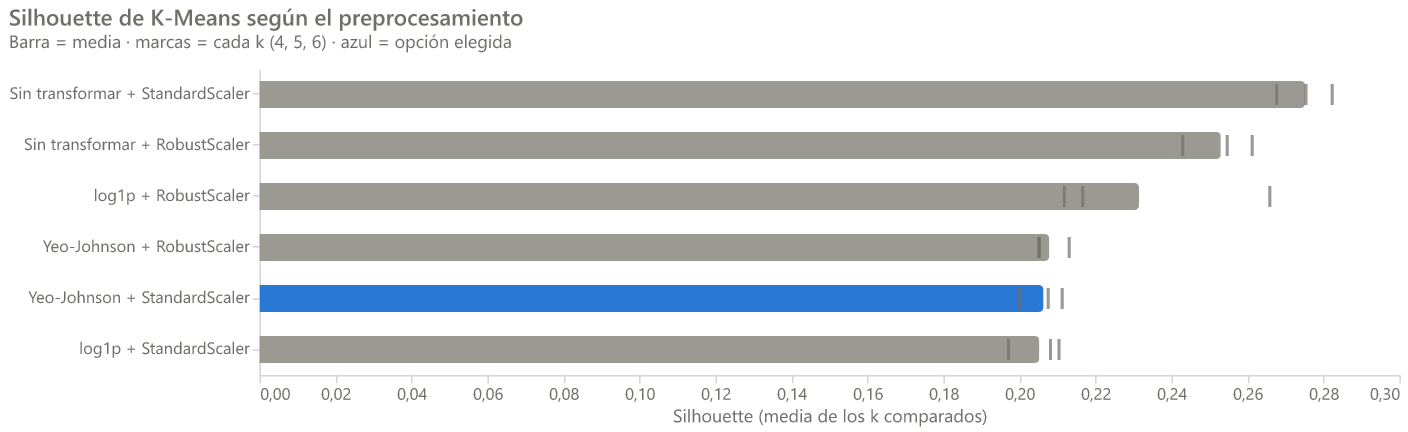

In [12]:
mc.transform_comparison_chart(comparison, chosen=(params.transform, params.scaler))

## 7. ¿Por qué no la opción con mayor silhouette?

- **Sin transformar** tiene el silhouette más alto, pero F y M siguen con asimetría > 3 y con
  *k* = 6 aparece un clúster diminuto: los grupos los definen los valores extremos.
- **`log1p` + RobustScaler** gana entre las opciones transformadas, pero RobustScaler divide
  por el rango intercuartílico y deja dispersiones distintas en cada feature. Veamos cuál pesa
  más y qué clúster pequeño aparece.

In [13]:
robust = make_preprocessor("log1p", "robust").fit_transform(features)
print("Desviación de cada feature tras log1p + RobustScaler:")
print(robust.std(ddof=0).round(2).to_dict())

labels = KMeans(n_clusters=4, n_init=10, random_state=config.random_state).fit_predict(robust)
features.groupby(labels).median().assign(
    pct_socios=pd.Series(labels).value_counts(normalize=True).sort_index()
)

Desviación de cada feature tras log1p + RobustScaler:
{'L': 0.57, 'R': 0.58, 'F': 0.6, 'M': 0.68, 'C': 0.91}


,L,R,F,M,C,pct_socios
0,34.53,5.83,4.00,"6,117.00",0.54,0.25
1,51.06,1.00,17.00,"24,646.00",0.72,0.38
2,37.78,7.57,4.00,"5,220.00",0.79,0.32
3,55.69,2.47,10.00,"14,565.00",1.24,0.05


C queda con más del 50 % de dispersión extra frente a L, R y F, y el clúster más pequeño
(~5 %) son justamente los socios con **C > 1** (tarifas premium). El silhouette sube porque el
escalado le da más peso a C, no porque exista más estructura.

**Decisión: Yeo-Johnson + StandardScaler.** Asimetría < 0,1 en las cinco features, el mismo peso
para todas y un silhouette equivalente al de las demás opciones transformadas. Queda fijada en
`configs/params.yaml` → `preprocessing`.

## 8. Preprocesador final

In [14]:
preprocessor = make_preprocessor(params.transform, params.scaler)
scaled = preprocessor.fit_transform(features)
pd.DataFrame(
    {
        "asimetría antes": skewness(features),
        "asimetría después": skewness(scaled),
        "media": scaled.mean(),
        "desviación": scaled.std(ddof=0),
    }
).round(3)

,asimetría antes,asimetría después,media,desviación
L,0.52,-0.04,0.00,1.00
R,1.21,0.02,-0.00,1.00
F,3.20,0.09,0.00,1.00
M,3.87,0.01,-0.00,1.00
C,0.98,-0.04,0.00,1.00


alt.LayerChart(...)
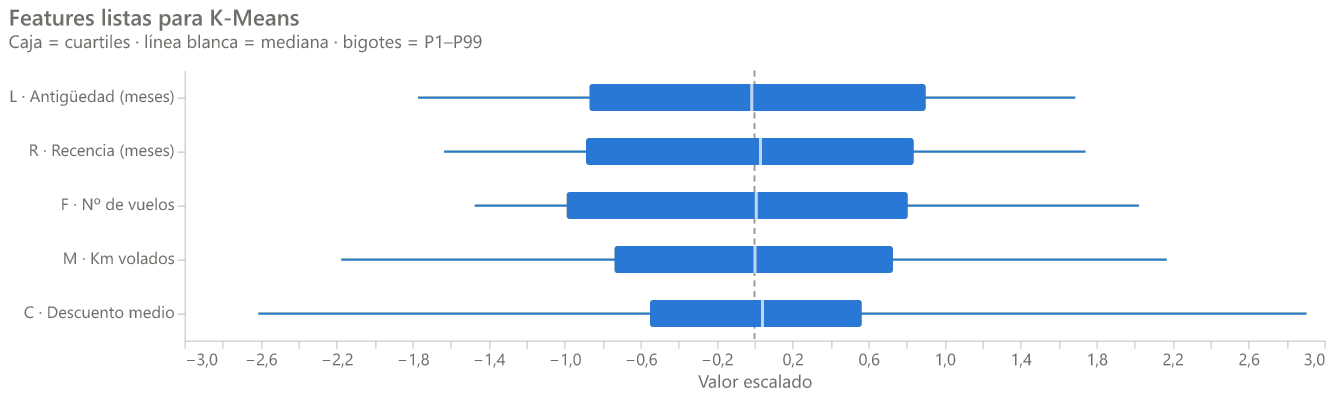

In [15]:
mc.scaled_distribution_chart(scaled)

## 9. Serialización

El `Pipeline` se guarda con joblib para aplicar exactamente la misma transformación al entrenar
K-Means y al asignar nuevos socios a un segmento.

In [16]:
saved = load_preprocessor(config.preprocessor_file)
reloaded = saved.transform(features)
pd.testing.assert_frame_equal(reloaded, scaled)
saved_scaled = pd.read_parquet(config.scaled_file)
pd.testing.assert_frame_equal(
    saved_scaled[list(LRFMC_COLUMNS)], scaled.reset_index(drop=True), check_dtype=False
)
print(saved)
print(f"{config.preprocessor_file.name} reproduce la transformación de {len(scaled):,} socios.")

Pipeline(steps=[('transform', PowerTransformer(standardize=False)),
                ('scale', StandardScaler())])
preprocessor.joblib reproduce la transformación de 62,044 socios.


## Conclusiones

- Las cinco métricas LRFMC se calculan para los **62.044 socios** sin nulos ni infinitos.
- `revenue_trend` acotado en [−1, 1] separa con claridad a los socios que dejaron de volar.
- **Yeo-Johnson + StandardScaler** deja las features simétricas, centradas y con el mismo peso.
  Las opciones con mayor silhouette lo consiguen por valores extremos o por ponderar de más una
  variable.
- Siguiente paso: elegir el número de segmentos *k* (notebook 04, Fase 6).